**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**06 | IMU–FE Timebase and Numerical Alignment Audit**

![Original Essex IMU and FE source timebase research workflow](../../images/06_workflow.svg)

**Objective:** Audit numerical IMU and FE column coverage and source time-vector consistency across the full 40-participant Essex dataset.

**Source:** Hollinger et al. (2026), *Scientific Data*, [10.1038/s41597-026-07429-3](https://doi.org/10.1038/s41597-026-07429-3); [original Figshare v13](https://doi.org/10.6084/m9.figshare.30225739.v13).

**Executed results:** All **1,897 source identities** matched; all **1,897 IMU records** contained 42 finite labelled channels, and **1,729 FE records** contained numeric `e1/e3`. The original registry classified **168 FE fields as empty**; the reader's narrow empty-object check recognised 24 and flagged 144 as `UNEXPECTED_NONEMPTY`. This discrepancy concerns decoded representations, not evidence that the original missingness count is wrong.

**Time-grid result:** All 1,729 nonempty FE records differed from the **assumed fixed index slice `IMU[::10]`**. The observed original time-coordinate ranges (IMU 1–101, FE 1–100 in the displayed examples) require a direct source-value/index matching test; their temporal correspondence has **not** been disproven.

**Interpretation:** Full-cohort Python numeric reading succeeded, while FE empty-object reconciliation and original time-coordinate mapping remain independent quality checks. No original numeric export or predictive model fitting was performed.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

import json
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, fetch_version_manifest,
    find_published_file, ensure_source_file,
    inspect_matlab_archive, extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_timebase_audit import (
    EXPECTED_CHANNELS, COMPONENTS, SENSORS,
    audit_original_source, summarise_alignment,
)

plot_style(font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5, label_weight="normal",
    tick_size=11, legend_size=10, figure_dpi=100,
    figure_size=(9, 4))
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
output_dir = study_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Original source:", ARTICLE_ID, ARTICLE_VERSION)
print("Evidence output:", output_dir)

Original source: 30225739 13
Evidence output: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Python MATLAB Table Reader**

Use Google Colab with Python **3.11–3.13** and the `mat-io==1.0.1` distribution (imported as `matio`). The installation cell uses its binary wheel without automatically replacing the runtime's NumPy, SciPy or pandas dependencies.

The [mat-io reader](https://pypi.org/project/mat-io/1.0.1/) supports MATLAB-object decoding directly in Python; MATLAB Desktop is not needed for this analysis.

In [3]:
# ================ 02. Install the Pinned MATLAB Object Reader ================

%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"

from matio import load_from_mat

assert version("mat-io") == "1.0.1"
print("Python MATLAB reader:", version("mat-io"))

Python MATLAB reader: 1.0.1


**03. Original Dataset and Integrity Checks**

Retrieve the original published `MATLAB.zip` and match its SHA256 to the source-provenance report. The 40 participant MAT files are extracted into the study's raw-data directory; the published archive is not replaced with the smaller two-activity derivative.

In [4]:
# ================ 03. Verify and Restore the Original Source =================

source_gate = json.loads(
    (output_dir / "02_record_provenance_and_quality_gate.json")
    .read_text(encoding="utf-8")
)
prior_gate = json.loads(
    (output_dir / "05_python_first_quality_gate.json")
    .read_text(encoding="utf-8")
)
assert source_gate["source_article_id"] == ARTICLE_ID
assert source_gate["version"] == ARTICLE_VERSION
assert source_gate["source_registry_gate"] == "PASSED"
assert prior_gate["source_integrity"] == "PASSED"
assert prior_gate["source_sha256"] == source_gate["archive_sha256"]

_, published_files = fetch_version_manifest()
archive_info = find_published_file(published_files, "MATLAB.zip")
source_zip, source_hash = ensure_source_file(archive_info, raw_dir)
assert source_hash["sha256"] == source_gate["archive_sha256"]
zip_inventory = inspect_matlab_archive(
    source_zip, expected_mat_files=40
)
mat_files = extract_matlab_files(
    source_zip, mat_dir, zip_inventory
)
assert len(mat_files) == 40
print("Source integrity verified:", source_hash["sha256"])

Source integrity verified: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d


**04. Original Trial Registry**

The original analytical unit is a `Data` record associated with a specific participant, source file, zero-based file-local index, activity and `UpdatedTrialID`. The existing registry fixes all 1,897 record identities before timebase interpretation.

In [5]:
# ============== 04. Original Trial and FE Missingness Registry ===============

registry = pd.read_csv(
    output_dir / "02_original_record_registry.csv",
    dtype={
        "subject_id": "string", "source_file": "string",
        "local_record_key": "string", "task": "string",
        "updated_trial_id": "string", "fe_representation": "string",
    },
)
registry_status = check_record_registry(registry, source_gate)
assert registry_status["records"] == 1897
assert registry_status["participants"] == 40
assert {p.stem.lower() for p in mat_files} == set(
    registry["subject_id"]
)
assert registry["fe_representation"].eq("empty").sum() == 168
print("Original records:", len(registry))
print("Source FE-empty representations: 168")

Original records: 1897
Source FE-empty representations: 168


**05. Original IMU and FE Column Contract**

The executed Python pilot identified one `timestep` field and 42 named accelerometer/gyroscope channels from seven sensor locations in each 101-row IMU table. In FE, `e1` and `e3` were finite numeric columns, while `timestep` was an object-typed column.

The named channel contract is independently checked against the saved pilot schema rather than inferred from column positions.

In [6]:
# ============== 05. Validate the Original Sensor and FE Schema ===============

schema = pd.read_csv(
    output_dir / "05_python_first_column_schema.csv"
)
imu_schema = schema.loc[schema["modality"] == "IMU"]
fe_schema = schema.loc[schema["modality"] == "FE"]
imu_names = set(imu_schema["original_column_name"])
fe_names = set(fe_schema["original_column_name"])
assert imu_names == set(EXPECTED_CHANNELS) | {"timestep"}
assert fe_names == {"timestep", "e1", "e3"}
assert len(EXPECTED_CHANNELS) == 42
assert len(COMPONENTS) == 6 and len(SENSORS) == 7
assert imu_schema.loc[
    imu_schema["original_column_name"] != "timestep",
    "is_real_finite_numeric"
].all()
assert fe_schema.loc[
    fe_schema["original_column_name"].isin(["e1", "e3"]),
    "is_real_finite_numeric"
].all()

channel_contract = pd.DataFrame([
    {"original_column_name": label,
     "signal_component": label.rsplit("_", 1)[0],
     "sensor_code": label.rsplit("_", 1)[1]}
    for label in EXPECTED_CHANNELS
])
channel_contract.to_csv(
    output_dir / "06_imu_channel_contract.csv", index=False
)
display(channel_contract.head(14))
print("Original numeric IMU channel names:", len(channel_contract))

,original_column_name,signal_component,sensor_code
0,accel_x_PEL,accel_x,PEL
1,accel_x_RTH,accel_x,RTH
2,accel_x_LTH,accel_x,LTH
3,accel_x_RSK,accel_x,RSK
4,accel_x_LSK,accel_x,LSK
5,accel_x_RFT,accel_x,RFT
6,accel_x_LFT,accel_x,LFT
7,accel_y_PEL,accel_y,PEL
8,accel_y_RTH,accel_y,RTH
9,accel_y_LTH,accel_y,LTH


Original numeric IMU channel names: 42


**06. Complete Source-Linked Numerical Audit**

Decode all original source records and validate 42 source-labelled IMU signal columns and finite `e1/e3` targets separately from their original time columns. Each record is matched against the source registry.

The recorded census found **1,897 valid IMU records**, **1,729 numeric FE records** and no file reader errors. Of 168 registry-empty FE fields, 24 were recognised by the current empty-type test; the remaining 144 need source-representation reconciliation rather than automatic assignment of FE targets.

In [7]:
# ======== 06. Audit Numerical Channels and Timebases for All Records =========

record_audit, reader_errors, example = audit_original_source(
    load_from_mat, mat_dir, registry
)
assert len(record_audit) == 1897
assert record_audit["local_record_key"].is_unique

record_audit.to_csv(
    output_dir / "06_original_numeric_record_audit.csv", index=False
)
reader_errors.to_csv(
    output_dir / "06_reader_errors.csv", index=False
)
print("Full original source records audited:", len(record_audit))
print("Files with reader errors:", len(reader_errors))
display(record_audit[[
    "subject_id", "task", "imu_status", "fe_status",
    "imu_timestep_status", "fe_timestep_status",
    "time_alignment",
]].head(20))

Full original source records audited: 1897
Files with reader errors: 0


,subject_id,task,imu_status,fe_status,imu_timestep_status,fe_timestep_status,time_alignment
0,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
1,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
2,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
3,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
4,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
5,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
6,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
7,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
8,subj04,CounterJumps,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS
9,subj04,Running,VALID_CHANNELS,VALID_STRAIN_COLUMNS,VALID_ORIGINAL_NUMERIC,VALID_ORIGINAL_NUMERIC,NUMERIC_TIME_GRID_DIFFERS


**07. Participant and Activity Coverage**

The source-level census reports numerical channel availability, empty FE fields and verified original trial identity separately for each participant and movement activity. This prevents a large aggregate count from concealing participants or activities with missing targets.

In [8]:
# ========== 07. Source Numeric Coverage by Participant and Activity ==========

def coverage(frame, by):
    return frame.groupby(by).agg(
        source_records=("local_record_key", "size"),
        valid_identities=("identity_valid", "sum"),
        numeric_imu=("imu_status", lambda s: s.eq("VALID_CHANNELS").sum()),
        numeric_fe=("fe_status", lambda s: s.eq("VALID_STRAIN_COLUMNS").sum()),
        source_fe_empty=("fe_status", lambda s: s.eq("EXPECTED_EMPTY").sum()),
        time_grid_matches=("time_alignment",
                           lambda s: s.eq("NUMERIC_TIME_GRID_MATCH").sum()),
    ).reset_index()

participant_coverage = coverage(record_audit, "subject_id")
activity_coverage = coverage(record_audit, "task")
participant_coverage.to_csv(
    output_dir / "06_participant_numeric_coverage.csv", index=False
)
activity_coverage.to_csv(
    output_dir / "06_activity_numeric_coverage.csv", index=False
)
display(activity_coverage)
print("Participant rows:", len(participant_coverage))

,task,source_records,valid_identities,numeric_imu,numeric_fe,source_fe_empty,time_grid_matches
0,BilateralHopping,351,351,351,300,24,0
1,CounterJumps,358,358,358,331,0,0
2,Running,360,360,360,333,0,0
3,SquatJumps,360,360,360,333,0,0
4,UnilateralHopping,348,348,348,321,0,0
5,Walking,120,120,120,111,0,0


Participant rows: 40


**08. Fixed-Index Timebase Comparison**

The experiment compares 11 FE coordinates against the *assumed* IMU sample indices `0, 10, ..., 100`. Across all **1,729 numeric FE records**, this specific equality test reported `NUMERIC_TIME_GRID_DIFFERS`. In an observed example, IMU time spans 1–101 while FE time spans 1–100.

These results establish that the **fixed positional assumption was not satisfied**; they do not establish that the original FE time values cannot be matched to *other* IMU source positions. The next temporal reconciliation evaluates the actual original coordinates without interpolation.

In [9]:
# ====== 08. Summarise Original Timebase Classes and Grid Correspondence ======

alignment_counts = (
    record_audit.groupby(
        ["fe_status", "time_alignment"], dropna=False
    ).size().rename("records").reset_index()
)
alignment_counts.to_csv(
    output_dir / "06_time_alignment_status.csv", index=False
)
time_cols = [
    "local_record_key", "subject_id", "task",
    "imu_timestep_status", "fe_timestep_status",
    "fe_time_entry_class", "imu_t0", "imu_tlast", "imu_tstep",
    "fe_t0", "fe_tlast", "fe_tstep",
    "time_alignment", "time_error",
]
for col in time_cols:
    if col not in record_audit:
        record_audit[col] = np.nan
time_examples = record_audit.loc[:, time_cols].copy()
time_examples.to_csv(
    output_dir / "06_timebase_metadata.csv", index=False
)
display(alignment_counts)
print("FE and IMU time vectors must agree before paired export.")

,fe_status,time_alignment,records
0,EXPECTED_EMPTY,NO_FE_TARGET,24
1,UNEXPECTED_NONEMPTY,INVALID_CHANNEL_OR_TARGET,144
2,VALID_STRAIN_COLUMNS,NUMERIC_TIME_GRID_DIFFERS,1729


FE and IMU time vectors must agree before paired export.


**09. Scientific Figures**

The first figure summarises source-derived numerical coverage and alignment decisions. The second shows genuine IMU and FE source columns from a validated original record, using their respective **sample indices** rather than assuming a shared timebase.

No simulated IMU waveform, interpolated FE strain or model prediction is plotted.

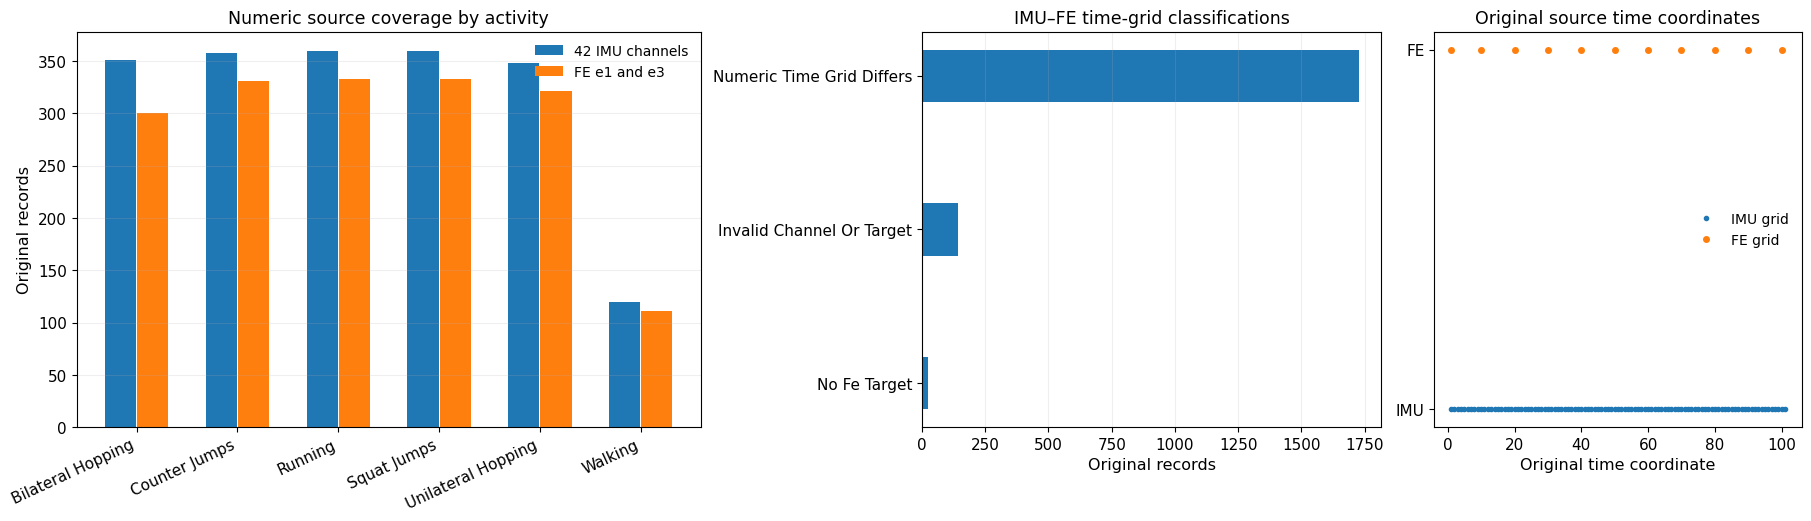

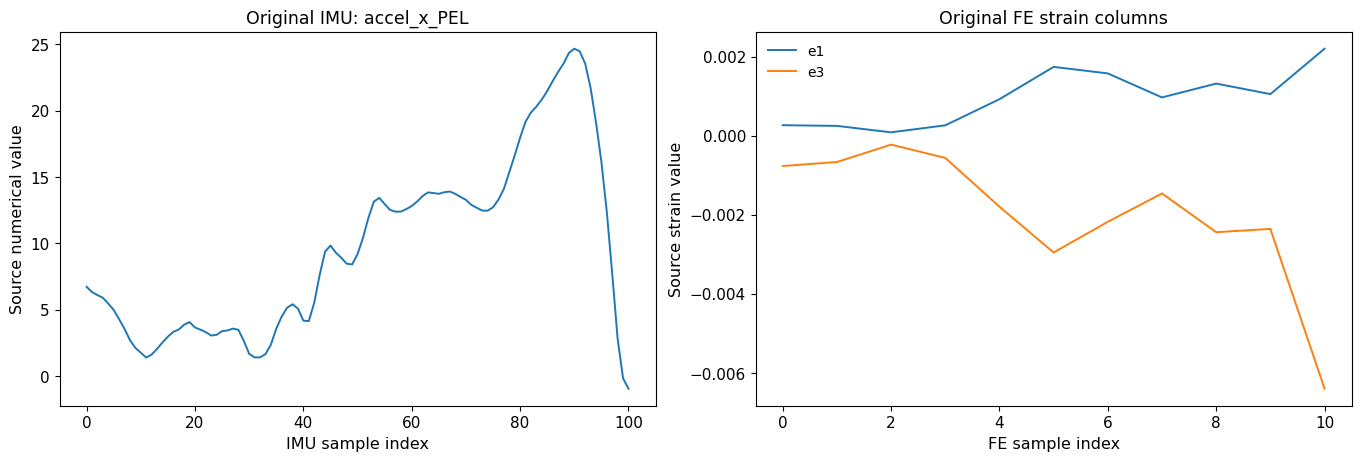

In [10]:
# ======== 09. Source Coverage, Time Grid and Authentic Signal Figures ========

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.1),
    gridspec_kw={"width_ratios": [1.7, 1.25, 1.0]},
    constrained_layout=True,
)
tasks = activity_coverage["task"]
positions = np.arange(len(tasks))
axes[0].bar(
    positions - 0.16, activity_coverage["numeric_imu"],
    width=0.31, label="42 IMU channels"
)
axes[0].bar(
    positions + 0.16, activity_coverage["numeric_fe"],
    width=0.31, label="FE e1 and e3"
)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(
    [name.replace("Hopping", " Hopping").replace("Jumps", " Jumps")
     for name in tasks], rotation=25, ha="right"
)
axes[0].set_title("Numeric source coverage by activity")
axes[0].set_ylabel("Original records")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2)

statuses = (
    record_audit.groupby("time_alignment")
    .size().sort_values(ascending=True)
)
yy = np.arange(len(statuses))
axes[1].barh(yy, statuses.values, height=0.34)
axes[1].set_yticks(yy)
axes[1].set_yticklabels(
    [s.replace("_", " ").title() for s in statuses.index]
)
axes[1].set_title("IMU–FE time-grid classifications")
axes[1].set_xlabel("Original records")
axes[1].grid(axis="x", alpha=0.2)

if example is not None and example["imu_time"] is not None:
    axes[2].plot(example["imu_time"], np.zeros(101), ".", label="IMU grid")
    if example["fe_time"] is not None:
        axes[2].plot(
            example["fe_time"], np.ones(11), "o", markersize=4,
            label="FE grid"
        )
    axes[2].set_yticks([0, 1])
    axes[2].set_yticklabels(["IMU", "FE"])
    axes[2].set_title("Original source time coordinates")
    axes[2].set_xlabel("Original time coordinate")
    axes[2].legend(frameon=False)
else:
    axes[2].text(
        0.5, 0.5, "No numeric source time axis available",
        ha="center", va="center", transform=axes[2].transAxes
    )
    axes[2].set_title("Original time-axis availability")
    axes[2].set_xticks([])
    axes[2].set_yticks([])
save_figure(fig, output_dir / "06_numeric_alignment_diagnostics.png")
plt.show()

fig2, axs = plt.subplots(1, 2, figsize=(13.5, 4.5),
                         constrained_layout=True)
if example is not None:
    axs[0].plot(
        np.arange(len(example["imu_signal"])),
        example["imu_signal"], linewidth=1.4
    )
    axs[0].set_title("Original IMU: " + example["imu_name"])
    axs[0].set_ylabel("Source numerical value")
    axs[0].set_xlabel("IMU sample index")
    axs[1].plot(np.arange(len(example["e1"])), example["e1"],
                label="e1", linewidth=1.4)
    axs[1].plot(np.arange(len(example["e3"])), example["e3"],
                label="e3", linewidth=1.4)
    axs[1].set_title("Original FE strain columns")
    axs[1].set_xlabel("FE sample index")
    axs[1].set_ylabel("Source strain value")
    axs[1].legend(frameon=False)
else:
    for axis in axs:
        axis.text(0.5, 0.5, "No validated numeric example",
                  ha="center", va="center", transform=axis.transAxes)
        axis.set_xticks([])
        axis.set_yticks([])
save_figure(fig2, output_dir / "06_original_numeric_examples.png")
plt.show()

**10. Executed Quality Gate and Research Outputs**

All **1,897 original source records** were audited, representing 40 participants and six movement activities. Numeric coverage includes **1,897 IMU 42-channel records** and **1,729 FE records** with numerical `e1/e3`. The source Registry contains 168 FE-empty fields: 24 reader-recognised empty objects and 144 requiring object-representation reconciliation.

The strict `IMU[::10]` time-grid comparison failed for all 1,729 nonempty FE records, so `numeric_full_export_ready: false` and `model_ready: false` remain accurate for this recorded implementation. These statuses must not be interpreted as evidence against a different source-coordinate mapping.

Ten `06_*` files preserve the source census, participant/activity coverage, reader errors, time metadata, two scientific figures and the original Quality Gate JSON. A Google Colab run packages these evidence files into a downloadable ZIP.

In [11]:
# ====== 10. Record the Scientific Quality Decision and Package Evidence ======

summary = summarise_alignment(record_audit, reader_errors)
quality = {
    "source_article": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "source_archive_sha256": source_hash["sha256"],
    "python_reader": "mat-io",
    "python_reader_version": version("mat-io"),
    "source_integrity": "PASSED",
    "full_source_numerical_audit": summary,
    "full_numeric_export_performed": False,
    "model_training_performed": False,
    "model_ready": False,
}
(output_dir / "06_numeric_timebase_quality_gate.json").write_text(
    json.dumps(quality, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame([summary]))
print("Full numeric export candidate:",
      summary["numeric_full_export_ready"])
print("Model readiness: FALSE")

expected = [
    "06_imu_channel_contract.csv",
    "06_original_numeric_record_audit.csv",
    "06_reader_errors.csv",
    "06_participant_numeric_coverage.csv",
    "06_activity_numeric_coverage.csv",
    "06_time_alignment_status.csv",
    "06_timebase_metadata.csv",
    "06_numeric_alignment_diagnostics.png",
    "06_original_numeric_examples.png",
    "06_numeric_timebase_quality_gate.json",
]
missing = [p for p in expected if not (output_dir / p).is_file()]
if missing:
    raise FileNotFoundError("Missing original source evidence: "
                            + ", ".join(missing))
print("Scientific output files:", len(expected))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="06"
)

,source_records,participants,source_identical,reader_error_files,imu_42_channel_records,fe_e1_e3_records,source_empty_fe_records,paired_numeric_records,numerically_matching_time_grids,time_grid_unresolved_records,time_grid_mismatched_records,numeric_full_export_ready,physical_units_independently_verified,model_ready
0,1897,40,True,0,1897,1729,24,1729,0,0,1729,False,False,False


Full numeric export candidate: False
Model readiness: FALSE
Scientific output files: 10
------------------------------------------------------------------------
Notebook stage: 06
Files packaged: 10
  + 06_activity_numeric_coverage.csv
  + 06_imu_channel_contract.csv
  + 06_numeric_alignment_diagnostics.png
  + 06_numeric_timebase_quality_gate.json
  + 06_original_numeric_examples.png
  + 06_original_numeric_record_audit.csv
  + 06_participant_numeric_coverage.csv
  + 06_reader_errors.csv
  + 06_time_alignment_status.csv
  + 06_timebase_metadata.csv
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_06_Outputs.zip
GitHub Commit/Push performed: NO
